# Porto Seguro Safe Driver Prediction – 05 Kaggle Submission (extra)

**Goal:** compare the project's final model with the competition. The official project evaluation is notebook
04: the held-out test part of `train.csv`, test Gini 0.281. Kaggle's own test set has no labels. A prediction
file can still be submitted to the closed competition (late submission), and Kaggle returns the Gini on its
public and private test sets. This makes the result directly comparable with the leaderboard.

**Rules for this notebook**
- The model and all its hyperparameters were fixed in notebook 03 and evaluated in notebook 04. Nothing here is
  tuned, and the Kaggle score is **never** used to change the model (that would turn Kaggle's test set into a
  validation set).
- As in the competition, the final model is refitted on **all** 595,212 rows of `train.csv`. The model choice
  is finished, so the 20% test part is no longer needed for evaluation and can serve as extra training data.
- Kaggle's `test.csv` is used only to create the submission (course rule: test data only for the competition).

**Workflow**
1. Setup: imports and shared project code
2. Load `train.csv` and Kaggle's `test.csv`
3. Same distribution? Compare the two files
4. Refit the final model on all of `train.csv`
5. Predict Kaggle's test set and check the predictions
6. Write the submission file
7. Kaggle result and comparison with the leaderboard

**Prerequisite:** `test.csv` from the
[Kaggle data page](https://www.kaggle.com/competitions/porto-seguro-safe-driver-prediction/data) in `project/Data/`.
**Run time:** about 5 minutes.

## 1. Setup

In [1]:
# 1. Imports, shared project code and settings
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# shared project code lives in ../src (same loading, preparation and final model as notebooks 01-04)
sys.path.insert(0, str(Path.cwd().parent))
from src.data_utils import DATA_PATH, load_data, split_features_target
from src.models import load_configuration, make_final_model

KAGGLE_TEST_PATH = DATA_PATH.parent / 'test.csv'
RESULTS_DIR = Path('../results')
SUBMISSION_PATH = RESULTS_DIR / '05_submission.csv'
plt.rcParams['figure.dpi'] = 90

## 2. Load `train.csv` and Kaggle's `test.csv`

In [2]:
# 2. Both files with the same recoding (-1 -> NaN); the Kaggle test file has an id but no target
train_data = load_data()
X_full, y_full = split_features_target(train_data)

kaggle_test = load_data(KAGGLE_TEST_PATH)
kaggle_ids = kaggle_test['id']
X_kaggle = kaggle_test.drop(columns=['id'])

print(f"train.csv: {X_full.shape[0]:,} rows, {X_full.shape[1]} features, claim rate {y_full.mean():.4%}")
print(f"test.csv:  {X_kaggle.shape[0]:,} rows, {X_kaggle.shape[1]} features, no target")
print("same feature columns in the same order:", list(X_kaggle.columns) == list(X_full.columns))
print("ids unique:", kaggle_ids.is_unique, "| ids shared with train.csv:",
      len(set(kaggle_ids) & set(train_data['id'])))

train.csv: 595,212 rows, 57 features, claim rate 3.6448%
test.csv:  892,816 rows, 57 features, no target
same feature columns in the same order: True


ids unique: True | ids shared with train.csv: 0


## 3. Same distribution?
A model only transfers to new data if that data comes from the same distribution. The share of missing
values and the mean of every feature are compared between the two files.

In [3]:
# 3. Share of missing values and feature means in train.csv vs Kaggle's test.csv
comparison = pd.DataFrame({
    'missing_train_%': X_full.isna().mean() * 100,
    'missing_test_%': X_kaggle.isna().mean() * 100,
    'mean_train': X_full.mean(),
    'mean_test': X_kaggle.mean(),
})
# difference of the means in units of the training standard deviation
comparison['mean_shift_in_std'] = (comparison['mean_test'] - comparison['mean_train']) / X_full.std()

print("Columns with missing values:")
print(comparison[comparison['missing_train_%'] > 0][['missing_train_%', 'missing_test_%']].round(2).to_string())
print(f"\nlargest mean shift over all 57 features: {comparison['mean_shift_in_std'].abs().max():.4f} std "
      f"({comparison['mean_shift_in_std'].abs().idxmax()})")

Columns with missing values:
               missing_train_%  missing_test_%
ps_ind_02_cat             0.04            0.03
ps_ind_04_cat             0.01            0.02
ps_ind_05_cat             0.98            0.98
ps_reg_03                18.11           18.11
ps_car_01_cat             0.02            0.02
ps_car_02_cat             0.00            0.00
ps_car_03_cat            69.09           69.10
ps_car_05_cat            44.78           44.84
ps_car_07_cat             1.93            1.94
ps_car_09_cat             0.10            0.10
ps_car_11                 0.00            0.00
ps_car_12                 0.00            0.00
ps_car_14                 7.16            7.15

largest mean shift over all 57 features: 0.0042 std (ps_ind_18_bin)


**Observations:**
- Both files have the same missing-value pattern. Every column with missing values differs by at most 0.06
  percentage points between them (e.g. `ps_car_03_cat` 69.09% vs 69.10%).
- The largest shift of a feature mean is 0.004 standard deviations. Kaggle's test set was clearly drawn from
  the same population as `train.csv`, so the evaluation on our own test part (notebook 04) should carry over.

## 4. Refit the final model on all of `train.csv`
Same configuration as in notebook 04 (saved by notebook 03): soft voting of the tuned logistic regression,
random forest and gradient boosting, without the `calc` features. Only the amount of training data changes:
595,212 rows instead of 476,169.

In [4]:
# 4. Fit the final model on 100% of train.csv
configuration = load_configuration()
final_model = make_final_model(list(X_full.columns), configuration)

start = time.time()
final_model.fit(X_full, y_full)
print(f"fitted on {len(y_full):,} rows in {time.time() - start:.0f} s")
print("gradient boosting stopped after",
      final_model.named_estimators_['gradient_boosting'][-1].n_iter_, "trees (early stopping)")

fitted on 595,212 rows in 223 s
gradient boosting stopped after 296 trees (early stopping)


## 5. Predict Kaggle's test set and check the predictions
Without labels, the predictions can still be checked for plausibility. The mean predicted probability should
be close to the claim rate of `train.csv` (3.64%), and the predictions on Kaggle's test set should have the same
distribution as the predictions on the training data.

In [5]:
# 5. Claim probabilities for the 892,816 Kaggle test drivers (and, for comparison, for train.csv)
kaggle_proba = final_model.predict_proba(X_kaggle)[:, 1]
train_proba = final_model.predict_proba(X_full)[:, 1]

# the two files have different sizes, so each one is summarized on its own
summary = pd.DataFrame({name: pd.Series(proba).describe(percentiles=[0.1, 0.5, 0.9, 0.99])
                        for name, proba in [('train.csv (fitted on)', train_proba),
                                            ("Kaggle's test.csv", kaggle_proba)]}).T
print(summary.round(4).to_string())
print(f"\nclaim rate in train.csv: {y_full.mean():.4f}")

                          count    mean     std     min     10%     50%     90%     99%     max
train.csv (fitted on)  595212.0  0.0365  0.0170  0.0088  0.0197  0.0327  0.0577  0.0959  0.2432
Kaggle's test.csv      892816.0  0.0365  0.0169  0.0088  0.0197  0.0327  0.0578  0.0958  0.2611

claim rate in train.csv: 0.0364


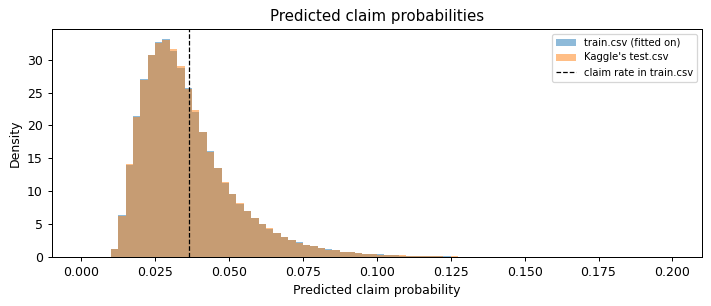

In [6]:
# 5. Distribution of the predicted claim probabilities
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 0.2, 81)
ax.hist(train_proba, bins=bins, density=True, alpha=0.5, label='train.csv (fitted on)')
ax.hist(kaggle_proba, bins=bins, density=True, alpha=0.5, label="Kaggle's test.csv")
ax.axvline(y_full.mean(), color='k', linestyle='--', linewidth=1, label='claim rate in train.csv')
ax.set(xlabel='Predicted claim probability', ylabel='Density', title='Predicted claim probabilities')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Observations:**
- The mean predicted probability on Kaggle's test set is 3.65%, almost exactly the claim rate of `train.csv`
  (3.64%), as expected from calibrated probabilities.
- The predictions on Kaggle's test set have practically the same distribution as on the training data (every
  quantile from 10% to 99% agrees within 0.0001). The model does not behave differently on the new drivers.
- Most drivers get a probability between 2% and 6%, and only 1% get more than 9.6%. As in notebook 04, the model
  shifts the odds but never reaches high certainty.
- Early stopping ended gradient boosting after 296 trees here, against 545 in notebook 04. With more data the
  internal 10% validation split contains different rows, and the stopping point depends on that split.

## 6. Write the submission file
Kaggle expects one row per test driver with the columns `id` and `target` (the predicted claim probability).
The file is written to `results/05_submission.csv`. It is not stored in the repository (about 15 MB, and it can
be recreated with this notebook).

In [7]:
# 6. Submission in the Kaggle format: id, target (probability of a claim)
submission = pd.DataFrame({'id': kaggle_ids, 'target': kaggle_proba})
submission.to_csv(SUBMISSION_PATH, index=False, float_format='%.6f')

# format checks: right number of rows, unique ids, probabilities between 0 and 1, no missing values
check = pd.read_csv(SUBMISSION_PATH)
print(f"written: {SUBMISSION_PATH} ({SUBMISSION_PATH.stat().st_size / 1e6:.1f} MB)")
print("columns:", list(check.columns), "| rows:", f"{len(check):,}", "| unique ids:", check['id'].is_unique,
      "| values in [0, 1]:", check['target'].between(0, 1).all(), "| missing:", int(check.isna().sum().sum()))
print(check.head().to_string(index=False))

written: ..\results\05_submission.csv (15.4 MB)
columns: ['id', 'target'] | rows: 892,816 | unique ids: True | values in [0, 1]: True | missing: 0
 id   target
  0 0.027891
  1 0.027327
  2 0.027761
  3 0.016137
  4 0.034958


## 7. Kaggle result and comparison with the leaderboard

**How to submit** (done by hand, with your own Kaggle account):
1. Open the [competition page](https://www.kaggle.com/competitions/porto-seguro-safe-driver-prediction) and
   choose *Late Submission*.
2. Upload `project/results/05_submission.csv`.
   (Or with the Kaggle API: `kaggle competitions submit -c porto-seguro-safe-driver-prediction -f
   ../results/05_submission.csv -m "soft voting LR + RF + GB"`.)
3. Kaggle shows a **public score** (about 30% of its test set) and a **private score** (the other 70%). The
   private score decided the final ranking.

**Result**

| Data | Gini |
|---|---|
| Our held-out test part of `train.csv` (notebook 04) | 0.281 (95% CI 0.265 – 0.298) |
| Kaggle public test set (about 30%) | 0.27256 |
| **Kaggle private test set (about 70%)** | **0.27911** |
| Place 100 of 5,157 teams, private test set | 0.29059 |
| Winning solution, private test set | 0.29698 |

**Observations:**
- The **private score of 0.279** lies inside the 95% confidence interval of notebook 04 (0.265 – 0.298) and only
  0.002 below its point estimate (0.281). Our own held-out test part predicted the performance on completely
  new drivers very well. This confirms that the evaluation protocol did not overfit.
- The public score (0.273) is lower, but it is computed on only about 30% of Kaggle's test drivers (about
  268,000) and is therefore noisier than the private one. Scaling the bootstrap interval of notebook 04
  (±0.017 for 119,000 drivers) to that size gives about ±0.011, so the difference of 0.007 is within the noise.
- The model was trained on **all** 595,212 rows of `train.csv`, so the whole labelled data was used. More data
  is not the reason for the gap to the leaderboard. Going from 381,000 rows (CV folds) to 476,000 rows
  (notebook 04) to 595,000 rows (here) changed the Gini only within its noise (0.274, 0.281, 0.279).
- The gap to the winner is 0.018, and to place 100 it is 0.011. The top solutions used much larger ensembles of
  gradient boosting libraries (XGBoost, LightGBM) and neural networks, extensive feature engineering (e.g.
  target encoding of `ps_car_11_cat`) and many tuning rounds against the leaderboard. This project
  deliberately used only the methods of the course and tuned only on the training part.
- Conclusion: with standard course methods and a clean protocol, the model reaches about 94% of the winning
  Gini (0.279 / 0.297).